# Praktikum Data Mining – Evaluasi Model Klasifikasi
## Tugas 4 – Eksperimen dan Rekomendasi
Kelompok 7 Data Mining

Anggota: Lutfiah Sahira (24343039), Imam Atthahira (24343037) , Rangga Dharma Putra (24343045). Mata kuliah: Data Mining· Dosen pengampu: Dr. Yeka Hendriyani, S.Kom., M.Kom. Program Studi Informatika, Departemen Teknik Elektronika, Fakultas Teknik, Universitas Negeri Padang


### Persiapan (data, model, dan prediksi dari langkah sebelumnya)

In [1]:
import numpy as np
import pandas as pd
rng = np.random.default_rng(42)
n = 500
amount = rng.lognormal(mean=5.0, sigma=1.0, size=n)
hour = rng.integers(0, 24, n)
new_device = rng.binomial(1, 0.25, n)
foreign_ip = rng.binomial(1, 0.12, n)
score = -4.5 + 0.45*(amount > 300) + 1.1*new_device + 1.5*foreign_ip + 0.7*(hour < 5)
prob = 1/(1+np.exp(-score))
isFraud = rng.binomial(1, prob)
df = pd.DataFrame({'amount':amount.round(2), 'hour':hour,
                   'new_device':new_device, 'foreign_ip':foreign_ip,
                   'isFraud':isFraud})

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
X = df.drop(columns='isFraud')
y = df['isFraud']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)
model = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

import matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             precision_score, recall_score, f1_score, classification_report)

y_prob = model.predict_proba(X_test)[:, list(model.classes_).index(1)]

### Sel T4

 Threshold  TP  FP  FN  Precision  Recall    F1
       0.2   2  32   3      0.059     0.4 0.103
       0.4   2  32   3      0.059     0.4 0.103
       0.5   2  32   3      0.059     0.4 0.103
       0.7   1  17   4      0.056     0.2 0.087


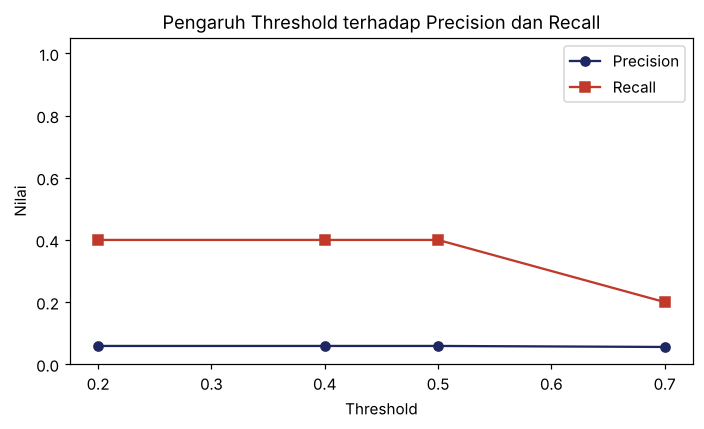

In [2]:
thr_list = [0.2, 0.4, 0.5, 0.7]
hasil = []
for th in thr_list:
    pr = (y_prob >= th).astype(int)
    t_n, f_p, f_n, t_p = confusion_matrix(y_test, pr, labels=[0,1]).ravel()
    hasil.append([th, t_p, f_p, f_n, precision_score(y_test, pr, zero_division=0),
                  recall_score(y_test, pr, zero_division=0), f1_score(y_test, pr, zero_division=0)])
tabel = pd.DataFrame(hasil, columns=['Threshold','TP','FP','FN','Precision','Recall','F1'])
print(tabel.round(3).to_string(index=False))
plt.figure(figsize=(6.5, 4))
plt.plot(tabel['Threshold'], tabel['Precision'], 'o-', color='#1E2761', label='Precision')
plt.plot(tabel['Threshold'], tabel['Recall'], 's-', color='#C0392B', label='Recall')
plt.xlabel('Threshold'); plt.ylabel('Nilai'); plt.ylim(0, 1.05); plt.legend()
plt.title('Pengaruh Threshold terhadap Precision dan Recall'); plt.tight_layout()
plt.savefig('fig_threshold.png', dpi=150); plt.show()

### Sel T4a

In [3]:
nilai, jumlah = np.unique(y_prob.round(4), return_counts=True)
for v, j in zip(nilai, jumlah):
    print(f'probabilitas {v:.4f}: {j} transaksi')
for th in thr_list:
    print(f'threshold {th}: alarm fraud = {(y_prob >= th).sum()}')

probabilitas 0.0000: 61 transaksi
probabilitas 0.1826: 55 transaksi
probabilitas 0.5424: 16 transaksi
probabilitas 0.8486: 15 transaksi
probabilitas 0.9391: 1 transaksi
probabilitas 1.0000: 2 transaksi
threshold 0.2: alarm fraud = 34
threshold 0.4: alarm fraud = 34
threshold 0.5: alarm fraud = 34
threshold 0.7: alarm fraud = 18


### Sel T4b

In [4]:
print('Total biaya = FN x rasio + FP (satuan = biaya satu FP)')
for rasio in [1, 5, 10, 15, 20, 50]:
    biaya = (tabel['FN'] * rasio + tabel['FP']).tolist()
    print(f'FN = {rasio:>2} x FP ->', dict(zip(tabel['Threshold'], biaya)))

Total biaya = FN x rasio + FP (satuan = biaya satu FP)
FN =  1 x FP -> {0.2: 35, 0.4: 35, 0.5: 35, 0.7: 21}
FN =  5 x FP -> {0.2: 47, 0.4: 47, 0.5: 47, 0.7: 37}
FN = 10 x FP -> {0.2: 62, 0.4: 62, 0.5: 62, 0.7: 57}
FN = 15 x FP -> {0.2: 77, 0.4: 77, 0.5: 77, 0.7: 77}
FN = 20 x FP -> {0.2: 92, 0.4: 92, 0.5: 92, 0.7: 97}
FN = 50 x FP -> {0.2: 182, 0.4: 182, 0.5: 182, 0.7: 217}
